<a href="https://colab.research.google.com/github/Rubi56/Dockerized-ble-gateway-raspberry-pi/blob/main/colab_stills.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 90s Kitchen — Colab stills
Use one Colab account, enable a GPU runtime, and upload `handoff/channel_intro/colab_input.zip`. Generate the host reference first; review it before generating shots. Outputs download as a ZIP. The notebook contains no API keys.


In [ ]:
%pip -q install -U 'transformers>=5.17' git+https://github.com/huggingface/diffusers accelerate 'pillow<13' safetensors
import json, os, shutil, zipfile
from pathlib import Path
from google.colab import files
import torch
from PIL import Image, ImageOps
assert torch.cuda.is_available(), 'Choose Runtime > Change runtime type > GPU first'
print('GPU:', torch.cuda.get_device_name(0), 'VRAM GiB:', round(torch.cuda.get_device_properties(0).total_memory/2**30,1))
uploaded = {'colab_input.zip': None} if Path('/content/colab_input.zip').exists() else files.upload()
assert len(uploaded)==1 and next(iter(uploaded)).endswith('.zip'), 'Upload one studio ZIP'
work = Path('/content/katha_stills')
work.mkdir(exist_ok=True)
with zipfile.ZipFile(next(iter(uploaded))) as z:
    for item in z.infolist():
        target = (work/item.filename).resolve()
        assert target.is_relative_to(work.resolve()), 'Unsafe ZIP path'
    z.extractall(work)
manifest = json.loads((work/'manifest.json').read_text())
print(len(manifest['references']), 'references;', len(manifest['shots']), 'stills')


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
GPU: Tesla T4 VRAM GiB: 14.6
1 references; 3 stills


In [ ]:
from PIL import ImageOps
from diffusers import AutoPipelineForText2Image, AutoPipelineForImage2Image
pipe = AutoPipelineForText2Image.from_pretrained(
    manifest['model'], dtype=torch.float16, variant='fp16', use_safetensors=True
)
pipe.vae.enable_slicing()
pipe.enable_model_cpu_offload()
edit_pipe = AutoPipelineForImage2Image.from_pipe(pipe)
edit_pipe.enable_model_cpu_offload()
print('SDXL pipelines loaded with CPU offload.')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

SDXL pipelines loaded with CPU offload.


In [ ]:
# Generate the host first. Review it before making stills.
PHASE = 'refs'  # 'refs' or 'shots'
LIMIT = 1       # 0 = all missing images
fmt = manifest.get('format', {})
WIDTH, HEIGHT = fmt.get('width', 576), fmt.get('height', 1024)
items = manifest['references'] if PHASE=='refs' else manifest['shots']
done = 0
for item in items:
    dest = work/item['output']
    if dest.exists():
        continue
    source_paths = ([work/item['source_image']] if item.get('source_image') else []) if PHASE=='refs' else [work/'refs_front'/f'{key}.png' for key in item.get('refs',[])]
    missing = [str(p) for p in source_paths if not p.exists()]
    if missing:
        print('SKIP', item['id'], 'missing reference:', ', '.join(missing)); continue
    width, height = (512, 640) if PHASE=='refs' else (WIDTH, HEIGHT)
    prompt = item['prompt']
    if PHASE=='refs':
        prompt = 'Front view portrait of the same woman in the photo, same face, eyes, skin tone and long curly hair, deep red sari, warm smile, plain warm grey background.'
    kwargs = {'prompt':prompt,
              'generator':torch.Generator('cpu').manual_seed(item.get('seed', 1000+done)),
              'num_inference_steps':25, 'guidance_scale':6.0}
    if source_paths:
        source = Image.open(source_paths[0]).convert('RGB')
        if PHASE=='refs':
            source = source.crop((int(source.width*.215), int(source.height*.04), int(source.width*.78), int(source.height*.57)))
        kwargs['image'] = ImageOps.fit(source, (width, height), method=Image.Resampling.LANCZOS)
        kwargs['strength'] = 0.45 if PHASE=='refs' else 0.6
        if PHASE=='shots':
            kwargs['prompt'] = 'Same woman as the input photo, same face and hair. ' + prompt
        result = edit_pipe(**kwargs).images[0]
    else:
        result = pipe(width=width, height=height, **kwargs).images[0]
    dest.parent.mkdir(parents=True, exist_ok=True)
    result.convert('RGB').save(dest)
    print('SAVED', dest.relative_to(work))
    done += 1
    torch.cuda.empty_cache()
    if LIMIT and done>=LIMIT: break


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/11 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


SAVED refs_front/host.png


host.png


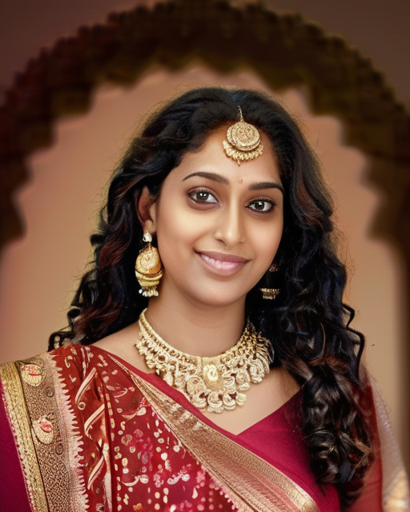

host_v1.png


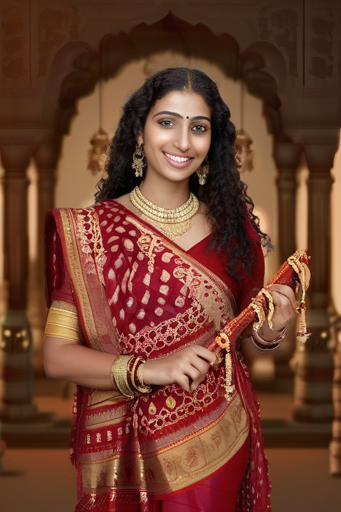

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from IPython.display import display
paths = sorted((work/'refs_front').glob('*.png')) if PHASE=='refs' else sorted((work/'stills').glob('*.png'))
for p in paths[:12]:
    print(p.name)
    preview = Image.open(p).copy(); preview.thumbnail((512,512)); display(preview)
archive = shutil.make_archive('/content/katha_stills_output', 'zip', work, '.')
files.download(archive)
